# Holter 전처리 v2: 3유도를 섞지 않고 그대로 저장 + 30초 조각 제외 표시

**목적**: 딥러닝(1D-CNN, LSTM/Transformer)이 파형을 직접 학습할 수 있게, 유도마다 정제한 **X·Y·Z 3유도를 섞지 않고 3채널 그대로** `.npy`로 저장한다. 세 유도를 어떻게 쓸지는 모델 단계에서 정한다.

- 대상은 최종 사용 환자 **445명** (`final_holter_ecg_1_cohort.ipynb` ⑥ → `cohort_final.csv`)
- 유도 구성: X·Y·Z 3유도 **423명**, X·Y 2유도(Z 없음) **22명**. Y는 445명 모두 있음
- 결과: `.npy` 모양 `(샘플 수, 3)`, 칸 순서는 항상 **X, Y, Z**. Z가 없는 환자는 Z 칸이 0
- 증강: 정제한 신호의 **앞 15시간(`-1`)·뒤 15시간(`-2`)**, 세 유도를 같은 시간 구간으로 자름. 원본 445개 + 증강본 890개 = 1,335개
- **30초 조각 제외는 표시만** 한다: 유도마다 R파를 세고, **두 유도 이상에서 R파가 3개 미만**인 조각을 `exclude = True`로 표에 남긴다. 파일에서 지우지 않는다 (학습할 때 뺌)
- 기존 `final_holter_ecg_3_preprocessing.ipynb`(PCA로 섞어 1채널)와 그 결과(`SCD_Holter_v2_pca/`)는 **건드리지 않는다**

| 출처 | 링크 |
|---|---|
| Swee 2026 (MUSIC, medRxiv 프리프린트) | Swee S, et al. *Multimodal Integration of Ambulatory ECG and Clinical Features for Sudden Cardiac Death and Pump Failure Death Prediction.* medRxiv 2026. [본문](https://www.medrxiv.org/content/10.64898/2026.04.21.26351421v2.full) · [코드](https://github.com/stswee/multimodal_aecg_clinicalfeatures) |
| Ramírez 2017 (MUSIC, 저널) | Ramírez J, et al. *T-Wave Morphology Restitution Predicts Sudden Cardiac Death in Patients With Chronic Heart Failure.* J Am Heart Assoc 2017;6:e005310. [PMC5524085](https://pmc.ncbi.nlm.nih.gov/articles/PMC5524085). 원문: "Baseline wander was removed with a 0.5 Hz high-pass filter" |

## 전처리 기준

| 순서 | 규칙 | 값 | 출처 |
|---|---|---|---|
| 1 | 유도 | 원본에 있는 유도를 모두 읽어 **X·Y·Z 순서의 3칸**에 이름으로 맞춰 넣음. Z가 없는 환자(22명)는 Z 칸을 **0**으로 둠 | 사용자 결정 2026-10-27 (Swee는 Y 하나, Ramírez는 PCA로 1개) |
| 2 | 기록 앞부분 | **30초 버림** | Swee 코드 `--skip_seconds` 기본값 |
| 3 | 대역통과 필터 | 4차 Butterworth **0.5–40 Hz**, `filtfilt`. **유도마다 따로** | Swee 2026, Ramírez 2017 (같은 범위) |
| 4 | 기저선 | **0.5 Hz 하이패스(3번 필터의 아래쪽)만.** 0.8초 median 제거는 **하지 않음** | Ramírez 2017. 시험에서 median 제거가 빠른 심박(100 이상)일 때 T파 크기를 ±20~30% 바꿈 |
| 5 | 정제 신호 저장 | `(샘플 수, 3)` **float16 `.npy`**, 단위 mV, 200 Hz. 파일 이름 = 환자 ID (`P0001.npy`). 기록 시작 30초 뒤부터 | 사용자 결정 2026-10-27 |
| 6 | 증강본 | 5번 신호의 **앞 15시간(`-1`)·뒤 15시간(`-2`)**을 세 유도 함께 잘라 같은 방식으로 저장 | 증강 규칙: `final_holter_ecg_2_augmentation.ipynb` |
| 7 | R파 검출 | NeuroKit2 `ecg_peaks` 기본 방법, **유도마다** 정제한 원본 기록 전체에서 한 번. 증강본은 원본의 R파 위치를 잘라서 씀 | Swee 2026 (Y 하나에서 한 번) → 유도마다로 넓힘 |
| 8 | 30초 조각 | 파일마다(원본, `-1`, `-2`) 시작점부터 겹치지 않게 30초씩. 끝에 남는 30초 미만은 조각에 넣지 않음 | Swee 2026 |
| 9 | **조각 제외 표시** | 조각마다 유도별 R파 수를 세고, **있는 유도 중 두 개 이상에서 R파 3개 미만이면 `exclude = True`**. 2유도 환자는 X·Y 둘 다 3개 미만일 때. **파일에서 지우지 않음** | R파 3개 미만: Swee 코드. 두 유도 이상(다수결): 사용자 결정 2026-10-27 (아래 설명) |
| 10 | 유도 기록 | 환자마다 원본 유도 이름(`leads`), 유도 수(`n_leads`), Z 있음(`has_z`)을 처리 기록에 남김 | 학습할 때 Z 칸이 0인 이유를 구분 |

**9번 "두 유도 이상" 규칙을 고른 이유 (445명 시험, 30초 조각 124만 개)**

| 규칙 | 빠지는 조각 | 문제 |
|---|---|---|
| Y 하나만 3개 미만 | 0.38% | Y 검출이 실패하면 X·Z가 멀쩡해도 뺌 |
| 모든 유도 3개 미만 | 0.24% | 한 유도가 잡음을 R파로 잘못 세면 잡음 조각이 남음 |
| **두 유도 이상 3개 미만** | **0.30%** | 위 두 문제를 대부분 피함. QRS가 아래로 향해 두 유도에서 검출이 실패하는 환자(예: P0575)는 일부 멀쩡한 조각이 빠짐 (3%) |
| 하나라도 3개 미만 | 0.63% | 멀쩡한 조각을 많이 뺌 (P0575는 42%) |

- R파 수 규칙은 잡음을 다 거르지 못한다. 잡음을 더 거르고 싶으면 신호 품질 지수(bSQI 등)가 필요하다.
- 유도별 R파 수를 모두 저장하므로, 학습할 때 다른 규칙(Y만, 모두, 하나라도)으로 바꿀 수 있다.

**Z 칸을 0으로 두는 이유**: 0은 "값이 없음"을 뜻하는 자리 채움이다. NaN이면 학습 계산이 전부 NaN이 된다. 학습할 때 어떻게 다룰지(0 채움, 표시, 일부러 가리기)는 모델 단계에서 정한다.

## 다른 기준과 다른 점

| 항목 | Swee 2026 | Ramírez 2017 | 이 노트북 |
|---|---|---|---|
| 유도 | Y 1개 | 3유도를 PCA로 섞어 1개 | **X·Y·Z 그대로 3개** |
| 기저선 | 0.5 Hz 하이패스 + 0.8초 median | 0.5 Hz 하이패스만 | **0.5 Hz 하이패스만** (Ramírez) |
| R파 검출 | Y에서 | (박동 경계 검출 + 눈으로 수정) | **유도마다** |
| 조각 제외 | R파 3개 미만 조각을 버림 | 박동 50개 미만 묶음을 버림 | **두 유도 이상 R파 3개 미만을 표시만** |
| 특징 계산 | 30초마다 28개 | T파 지표(TMR) | 안 함 (원파형 학습) |

노트북 3(PCA)과 비교: 유도를 섞지 않음, 기저선 median 없음, R파 수 표 추가, 결과 폴더 `SCD_Holter_v2_3lead/`, 처리 기록 `results/final_holter_ecg_v2/record_log.csv`.

## 결정 기록 (사용자가 정한 것만)

| 날짜 | 결정 | 근거 |
|---|---|---|
| 2026-10-27 | 3유도를 PCA로 섞지 않고 **X·Y·Z 3채널 그대로** 저장. 3유도 환자는 3개, 2유도 환자는 2개를 모델이 보고 학습 | PCA 합치기는 저널 근거를 찾지 못함. 여러 유도를 채널로 넣는 방식은 12유도 심전도 딥러닝에서 흔함 (예: Ribeiro 2020 *Nat Commun*) |
| 2026-10-27 | 전처리·증강에서는 3유도를 모두 살려 저장만 함. **3유도를 어떻게 쓸지(섞기, 빠진 Z 처리 등)는 모델 단계에서 결정** | 사용자 결정 |
| 2026-10-27 | Z가 없는 22명은 저장할 때 Z 칸을 0으로 두고 처리 기록에 `has_z`로 표시 | `(샘플 수, 3)` 모양 통일 |
| 2026-10-27 | 기존 PCA 노트북과 결과는 그대로 두고 v2 노트북을 새로 만듦 | 사용자 요청 |
| 2026-10-27 | **기저선은 0.5 Hz 하이패스만** (0.8초 median 제거 뺌) | Ramírez 2017 (MUSIC, 저널). median 제거가 빠른 심박에서 T파를 바꾸는 것을 시험으로 확인 |
| 2026-10-27 | **30초 조각 제외: 유도마다 R파를 세서 두 유도 이상에서 3개 미만이면 표시만** (파일에서 지우지 않음) | 445명 시험에서 Y만·모두·하나라도 규칙과 비교 (위 표). 팀원 제안 |

## 검토 중 (제안, 아직 결정 안 함)

| 항목 | 내용 |
|---|---|
| 결측 유도 처리 근거 | 0 채움, "Z 없음" 표시, 학습 중 일부러 가리기(lead dropout)의 논문 근거 찾기 |
| 잡음 거르기 보강 | R파 수 규칙이 못 거르는 잡음(평평한 신호 일부, 움직임 잡음)을 신호 품질 지수로 거를지 |
| R파 검출 극성 | QRS가 아래로 향하는 환자(예: P0575)에서 NeuroKit이 R파를 놓침 |
| 22명 성능 따로 보기 | 학습 후 Z가 없는 22명의 예측 성능을 따로 확인 |
| Y만 쓴 모델과 비교 | 같은 파일의 Y 칸으로 Swee 조건 기준선을 만들어 3유도와 비교 |

## 진행 상황

| 셀 | 내용 | 상태 | 날짜 |
|---|---|---|---|
| ① | 설정 | | |
| ② | 기록 1개 전처리 + R파 함수 | | |
| ③ | 환자 1명 처리 + 시험 (3유도 1명, 2유도 1명) | | |
| ③-2 | 저장한 `.npy` 그림 | | |
| ④ | 전체 실행 (445명) | | |
| ⑤ | 결과 확인 | | |
| ⑥ | 구글 드라이브 업로드 준비 | | |

In [1]:
# ① 설정: 경로, 전처리 상수, 처리할 환자 목록
from pathlib import Path
import resource
import shutil
import time
import warnings

import matplotlib.pyplot as plt
import neurokit2 as nk
import numpy as np
import pandas as pd
import scipy.signal as sp
import wfdb
from joblib import Parallel, delayed
from tqdm.auto import tqdm

plt.rcParams["font.family"] = "NanumGothic"       # 그림의 한글 (다른 전처리 노트북과 같은 글꼴)
plt.rcParams["axes.unicode_minus"] = False
warnings.filterwarnings("ignore", category=UserWarning)

# 경로
RAW_DIR = Path("/mnt/c/data/music/Holter_ECG")            # PhysioNet 원본 (.hea / .dat)
OUT_DIR = Path("/mnt/c/data/music/SCD_Holter_v2_3lead")   # 결과 폴더 = 드라이브에 통째로 올릴 폴더
CLEAN_DIR = OUT_DIR / "clean_signal"                      # 환자마다 .npy: (샘플 수, 3) X·Y·Z float16
RPEAK_DIR = OUT_DIR / "_rpeak_counts"                     # 환자마다 조각별 R파 수 CSV (중간 파일, ⑥에서 1개로 합치고 지움)
LOG_PATH = Path("../results/final_holter_ecg_v2/record_log.csv")    # 환자마다 1줄: 처리 상태, 유도, 시간
COHORT_PATH = Path("../results/final_holter_ecg/cohort_final.csv")  # 처리할 환자 = 최종 사용 환자 445명 (노트북 1 ⑥)

# 전처리 상수 (위 '전처리 기준' 표의 순서 번호)
CHANNELS = ["X", "Y", "Z"]  # 1. 저장할 칸 순서. 원본 유도를 이름으로 맞춰 넣고, 없는 유도 칸은 0
SKIP_SEC = 30               # 2. 기록 앞 30초 버림
BAND_HZ = (0.5, 40)         # 3·4. 대역통과 필터 범위 (아래쪽 0.5 Hz가 기저선 제거)
FILTER_ORDER = 4            # 3. 필터 차수
AUG_HOURS = 15              # 6. 증강본 길이: 앞 15시간(-1), 뒤 15시간(-2)
WINDOW_SEC = 30             # 8. 조각 길이
MIN_RPEAKS = 3              # 9. 이보다 R파가 적은 유도 = 그 조각에서 '심전도가 안 보이는 유도'
MIN_LOW_LEADS = 2           # 9. 이만큼 이상의 유도가 R파 부족이면 조각 제외 표시 (2유도 환자는 2개 = 둘 다)

EXPECTED_GB = 105           # 1,335개 예상 용량
LOG_COLUMNS = ["patient_id", "status", "error", "leads", "n_leads", "has_z", "fs", "n_samples_raw", "n_nan_raw",
               "n_samples_clean", "n_aug", "n_windows", "n_excluded", "rpeak_fail", "seconds", "peak_mem_gb"]

N_JOBS = 6                  # 동시에 처리할 환자 수. ③ 시험의 peak_mem_gb × N_JOBS가 RAM 16 GB 안에 들어가게 조정

CLEAN_DIR.mkdir(parents=True, exist_ok=True)
RPEAK_DIR.mkdir(parents=True, exist_ok=True)
LOG_PATH.parent.mkdir(parents=True, exist_ok=True)

# 처리할 기록 목록: RECORDS 파일의 Holter 기록(936개) 중 최종 사용 환자만
records_file = RAW_DIR.parent / "RECORDS"
holter_ids = [line.split("/")[-1] for line in records_file.read_text().split() if line.startswith("Holter_ECG/")]
cohort_ids = set(pd.read_csv(COHORT_PATH)["pid"])
record_ids = [r for r in holter_ids if r in cohort_ids]
assert len(record_ids) == len(cohort_ids), f"Holter 기록이 없는 환자: {sorted(cohort_ids - set(holter_ids))}"

free_gb = shutil.disk_usage(OUT_DIR).free / 1e9
print(f"Holter 기록 {len(holter_ids)}개 중 처리 대상 {len(record_ids)}명 · neurokit2 {nk.__version__} · wfdb {wfdb.__version__}")
print(f"저장 위치 여유 공간 {free_gb:.0f} GB (필요 약 {EXPECTED_GB} GB)")

Holter 기록 936개 중 처리 대상 445명 · neurokit2 0.2.13 · wfdb 4.3.1
저장 위치 여유 공간 228 GB (필요 약 105 GB)


/home/mingyu/poc-test/.venv/lib/python3.12/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


In [2]:
# ② 기록 1개 전처리 + R파: 읽기 → 앞 30초 버림 → 유도마다 0.5–40 Hz 필터 → X·Y·Z 3칸 / 유도마다 R파 → 30초 조각별 R파 수
def read_leads(record_id):
    """원본의 모든 유도를 mV로 읽음 → ((샘플 수, 유도 수) 신호, 샘플링 속도, 유도 이름 목록)"""
    record = wfdb.rdrecord(str(RAW_DIR / record_id))
    return record.p_signal, record.fs, record.sig_name


def bandpass_filter(signal, fs):
    """4차 Butterworth 0.5–40 Hz를 앞뒤로 한 번씩 걸음 (filtfilt: 파형 위치가 밀리지 않음)
    아래쪽 0.5 Hz가 숨쉬기·움직임으로 생기는 느린 기저선 흔들림을 없앰 (Ramírez 2017)"""
    nyquist = fs / 2
    b, a = sp.butter(FILTER_ORDER, [BAND_HZ[0] / nyquist, BAND_HZ[1] / nyquist], btype="band")
    return sp.filtfilt(b, a, signal)


def filter_leads(raw, fs):
    """(샘플 수, 유도 수) 원본 → 앞 30초를 버리고 유도마다 대역통과 필터"""
    trimmed = raw[int(SKIP_SEC * fs):]
    leads = np.empty(trimmed.shape, dtype=np.float32)
    for j in range(trimmed.shape[1]):
        leads[:, j] = bandpass_filter(trimmed[:, j], fs)
    return leads


def to_xyz_channels(leads, lead_names):
    """필터 후 유도들 → (샘플 수, 3) X·Y·Z 순서 배열. 유도를 이름으로 맞춰 넣고, 원본에 없는 유도 칸은 0
    처음 보는 유도 이름이면 ValueError → 그 환자는 오류로 기록됨"""
    channels = np.zeros((len(leads), len(CHANNELS)), dtype=np.float32)
    for j, name in enumerate(lead_names):
        channels[:, CHANNELS.index(name)] = leads[:, j]
    return channels


def preprocess_record(record_id):
    """기록 1개 → ((샘플 수, 3) 정제 신호 float32, 원본 유도 이름 목록, 기록 정보 dict)"""
    raw, fs, lead_names = read_leads(record_id)
    info = {"leads": "".join(lead_names), "n_leads": len(lead_names), "has_z": "Z" in lead_names,
            "fs": fs, "n_samples_raw": len(raw),
            "n_nan_raw": int(np.isnan(raw).sum())}           # 모든 유도의 NaN 합. 있으면 여기서 보임

    leads = filter_leads(raw, fs)
    del raw
    clean = to_xyz_channels(leads, lead_names)
    info["n_samples_clean"] = len(clean)
    return clean, lead_names, info


def detect_rpeaks(signal, fs):
    """유도 1개의 정제 신호 전체 → R파 위치(샘플 번호) 배열. NeuroKit2가 오류를 내면 None"""
    try:
        _, peaks = nk.ecg_peaks(signal, sampling_rate=fs)
        return np.asarray(peaks["ECG_R_Peaks"], dtype=np.int64)
    except Exception:
        return None


def count_per_window(rpeaks, start, n_samples, window):
    """원본 기준 R파 위치 → 파일 [start, start + n_samples) 안의 30초 조각마다 R파 수"""
    n_win = n_samples // window
    inside = rpeaks[(rpeaks >= start) & (rpeaks < start + n_win * window)] - start
    return np.bincount(inside // window, minlength=n_win)


def window_table(name, rpeaks_by_lead, start, n_samples, fs):
    """파일 1개 → 조각 1줄 표: 파일 이름, 조각 번호, 시작 샘플, 유도별 R파 수(없는 유도는 -1), 제외 표시"""
    window = WINDOW_SEC * fs
    n_win = n_samples // window
    table = pd.DataFrame({"file": f"{name}.npy", "window_idx": np.arange(n_win), "start_idx": np.arange(n_win) * window})
    for lead in CHANNELS:
        rpeaks = rpeaks_by_lead.get(lead)
        if lead not in rpeaks_by_lead:
            table[f"r_{lead}"] = -1                                       # 원본에 없는 유도
        else:
            table[f"r_{lead}"] = count_per_window(rpeaks if rpeaks is not None else np.array([], dtype=np.int64),
                                                  start, n_samples, window)
    counts = table[[f"r_{lead}" for lead in CHANNELS]]
    n_present = (counts >= 0).sum(axis=1)
    n_low = counts.apply(lambda c: c.between(0, MIN_RPEAKS - 1)).sum(axis=1)
    table["n_low_leads"] = n_low
    table["exclude"] = n_low >= np.minimum(MIN_LOW_LEADS, n_present)  # 9. 두 유도 이상 (2유도 환자는 둘 다)
    return table

In [3]:
# ③ 환자 1명 처리 함수 + 시험: 전처리 → .npy 저장 → 유도별 R파 → 원본·증강본 조각 표 → 처리 기록 1줄
def save_clean(signal, name):
    """(샘플 수, 3) 정제 신호를 float16 .npy로 저장. 파일 이름 = 환자 ID 또는 증강 ID"""
    np.save(CLEAN_DIR / f"{name}.npy", signal.astype(np.float16))


def augment_crops(n_samples, fs):
    """정제된 신호 길이 → [(번호, 시작, 끝)]: 앞 15시간(-1), 뒤 15시간(-2). 15시간 이하면 빈 목록"""
    crop_len = int(AUG_HOURS * 3600 * fs)
    if n_samples <= crop_len:
        return []
    return [(1, 0, crop_len), (2, n_samples - crop_len, n_samples)]


def process_patient(record_id):
    """환자 1명을 끝까지 처리하고 기록 1줄(dict)을 돌려줌. 오류가 나도 멈추지 않고 이유를 남김"""
    t0 = time.time()
    log = {"patient_id": record_id, "status": "ok", "error": ""}
    try:
        clean, lead_names, info = preprocess_record(record_id)
        fs = info["fs"]
        log.update(info)

        save_clean(clean, record_id)
        crops = augment_crops(len(clean), fs)
        for k, start, end in crops:   # 증강본: 정제된 원본에서 세 유도를 같은 시간 구간으로 잘라 저장
            save_clean(clean[start:end], f"{record_id}-{k}")
        log["n_aug"] = len(crops)

        # R파: 원본에 있는 유도마다 기록 전체에서 한 번 → 원본·증강본 조각 표에 같이 씀
        rpeaks_by_lead = {lead: detect_rpeaks(clean[:, CHANNELS.index(lead)], fs) for lead in lead_names}
        log["rpeak_fail"] = "".join(lead for lead, r in rpeaks_by_lead.items() if r is None)
        files = [(record_id, 0, len(clean))] + [(f"{record_id}-{k}", start, end - start) for k, start, end in crops]
        tables = pd.concat([window_table(name, rpeaks_by_lead, start, n, fs) for name, start, n in files])
        tables.insert(0, "pid", record_id)
        tables.to_csv(RPEAK_DIR / f"{record_id}.csv", index=False)

        original = tables[tables["file"] == f"{record_id}.npy"]
        log["n_windows"] = len(original)
        log["n_excluded"] = int(original["exclude"].sum())
    except Exception as e:
        log.update({"status": "error", "error": f"{type(e).__name__}: {e}"})
    log["seconds"] = round(time.time() - t0, 1)
    log["peak_mem_gb"] = round(resource.getrusage(resource.RUSAGE_SELF).ru_maxrss / 1e6, 2)   # 이 프로세스의 최대 메모리
    return log


TEST_IDS = ["P0307", "P0174"]   # P0307: 3유도(XYZ), 깨끗한 정상 동리듬 / P0174: 2유도(XY, Z 없음)

test_logs = pd.DataFrame([process_patient(r) for r in TEST_IDS]).set_index("patient_id")
display(test_logs.T)

for record_id in TEST_IDS:   # 환자마다 원본 1개 + 증강본 2개
    fs = test_logs.loc[record_id, "fs"]
    for path in sorted(CLEAN_DIR.glob(f"{record_id}*.npy")):
        signal = np.load(path)
        z_is_zero = not np.any(signal[:, 2])
        print(f"{path.name}: {signal.shape} {signal.dtype} · {len(signal) / fs / 3600:.2f}시간 · "
              f"{path.stat().st_size / 1e6:.0f} MB · Z 칸 전부 0: {z_is_zero}")
    table = pd.read_csv(RPEAK_DIR / f"{record_id}.csv")
    display(table.groupby("file").agg(조각=("window_idx", "size"), 제외=("exclude", "sum"),
                                      R_X중앙값=("r_X", "median"), R_Y중앙값=("r_Y", "median"), R_Z중앙값=("r_Z", "median")))

patient_id,P0307,P0174
status,ok,ok
error,,
leads,XYZ,XY
n_leads,3,2
has_z,True,False
fs,200,200
n_samples_raw,17278200,17278301
n_nan_raw,0,0
n_samples_clean,17272200,17272301
n_aug,2,2


P0307-1.npy: (10800000, 3) float16 · 15.00시간 · 65 MB · Z 칸 전부 0: False
P0307-2.npy: (10800000, 3) float16 · 15.00시간 · 65 MB · Z 칸 전부 0: False


P0307.npy: (17272200, 3) float16 · 23.99시간 · 104 MB · Z 칸 전부 0: False


,조각,제외,R_X중앙값,R_Y중앙값,R_Z중앙값
file,,,,,
P0307-1.npy,1800,0,37.0,37.0,37.0
P0307-2.npy,1800,0,33.0,33.0,34.0
P0307.npy,2878,0,36.0,36.0,36.0


P0174-1.npy: (10800000, 3) float16 · 15.00시간 · 65 MB · Z 칸 전부 0: True
P0174-2.npy: (10800000, 3) float16 · 15.00시간 · 65 MB · Z 칸 전부 0: True


P0174.npy: (17272301, 3) float16 · 23.99시간 · 104 MB · Z 칸 전부 0: True


,조각,제외,R_X중앙값,R_Y중앙값,R_Z중앙값
file,,,,,
P0174-1.npy,1800,0,43.0,42.0,-1.0
P0174-2.npy,1800,0,38.0,38.0,-1.0
P0174.npy,2878,0,40.0,40.0,-1.0


findfont: Font family 'NanumGothic' not found.


findfont: Font family 'NanumGothic' not found.


findfont: Font family 'NanumGothic' not found.


findfont: Font family 'NanumGothic' not found.


findfont: Font family 'NanumGothic' not found.


...

findfont: Font family 'NanumGothic' not found.


findfont: Font family 'NanumGothic' not found.


findfont: Font family 'NanumGothic' not found.


findfont: Font family 'NanumGothic' not found.


findfont: Font family 'NanumGothic' not found.


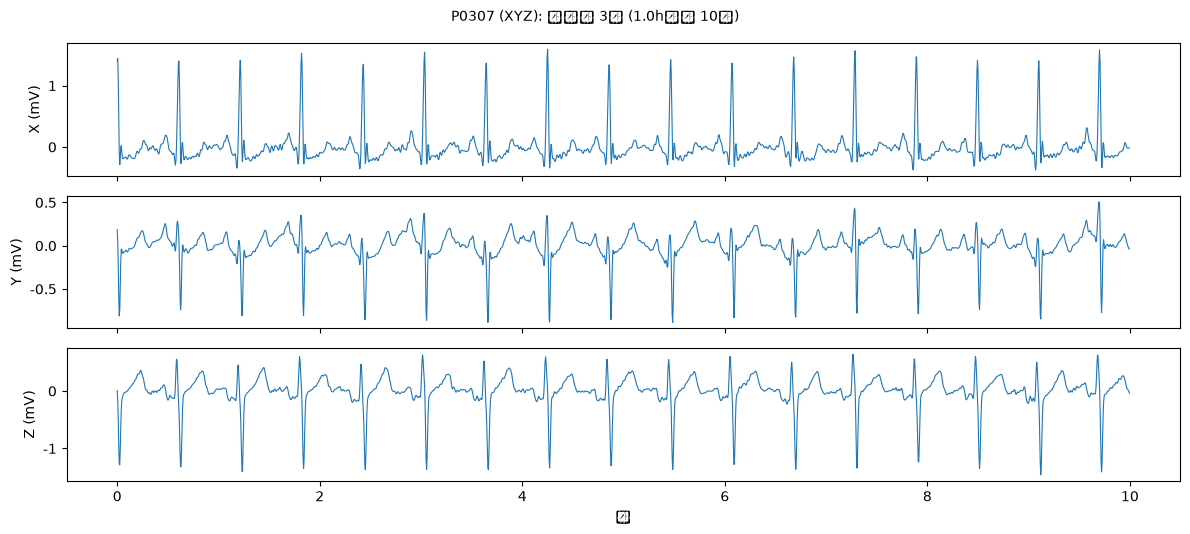

findfont: Font family 'NanumGothic' not found.


findfont: Font family 'NanumGothic' not found.


findfont: Font family 'NanumGothic' not found.


findfont: Font family 'NanumGothic' not found.


findfont: Font family 'NanumGothic' not found.


...

findfont: Font family 'NanumGothic' not found.


findfont: Font family 'NanumGothic' not found.


findfont: Font family 'NanumGothic' not found.


findfont: Font family 'NanumGothic' not found.


findfont: Font family 'NanumGothic' not found.


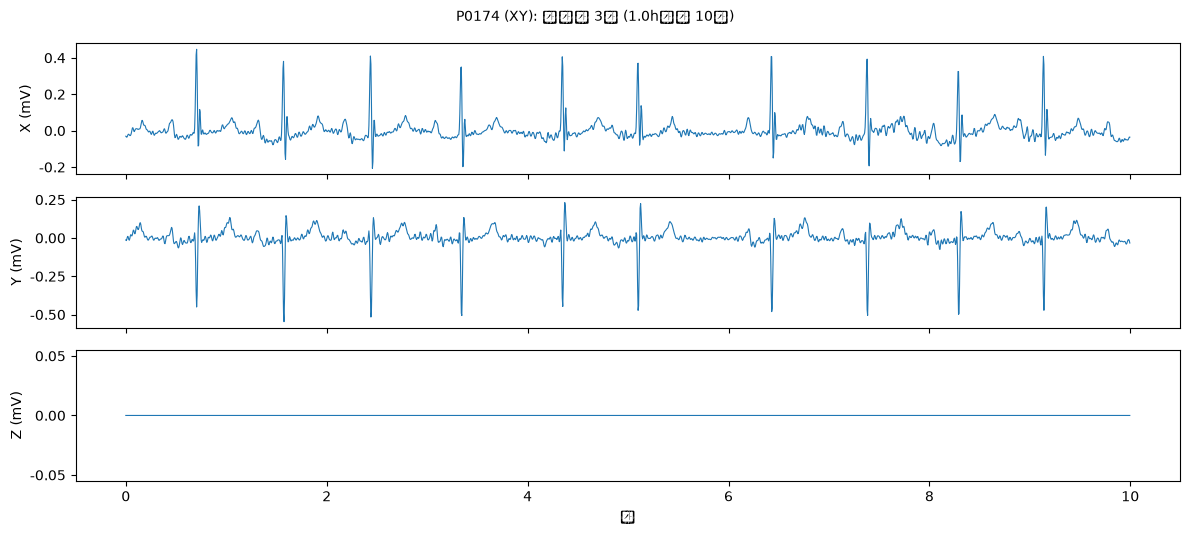

In [4]:
# ③-2 그림: 저장한 .npy를 다시 읽어 X·Y·Z 3칸을 같은 10초로 그림 (칸 순서, R파 방향, Z 칸 0 확인)
PLOT_START_H = 1.0        # 그릴 위치 (앞 30초를 버린 뒤 시각, 시간)
PLOT_SECONDS = 10

for record_id in TEST_IDS:
    fs = test_logs.loc[record_id, "fs"]
    signal = np.load(CLEAN_DIR / f"{record_id}.npy", mmap_mode="r")   # 필요한 부분만 읽음
    a = int(PLOT_START_H * 3600 * fs)
    b = a + PLOT_SECONDS * fs
    t = np.arange(b - a) / fs

    fig, axes = plt.subplots(len(CHANNELS), 1, figsize=(12, 1.8 * len(CHANNELS)), sharex=True)
    for ax, (j, name) in zip(axes, enumerate(CHANNELS)):
        ax.plot(t, signal[a:b, j], lw=0.8, color="tab:blue")
        ax.set_ylabel(f"{name} (mV)")
    axes[-1].set_xlabel("초")
    fig.suptitle(f"{record_id} ({test_logs.loc[record_id, 'leads']}): 저장한 3칸 ({PLOT_START_H}h부터 {PLOT_SECONDS}초)",
                 fontsize=10)
    fig.tight_layout()
    plt.show()

📝 **③ 결과 메모** (실행 후 적기)
- 처리 시간 (`seconds`) → 445명 예상 시간 = 시간 × 445 ÷ `N_JOBS`:
- 최대 메모리 (`peak_mem_gb`) → `N_JOBS` 몇으로 할지:
- `.npy` 6개 (환자 2명 × 원본, `-1`, `-2`)의 모양·dtype·길이·용량:
- P0174의 Z 칸이 전부 0인가, P0307의 Z 칸은 0이 아닌가:
- 조각 표: 조각 수, 제외 수, 유도별 R파 수 중앙값 (30초에 보통 30~40):
- ③-2 그림: X·Y·Z 순서가 맞는가, 잡음이 심한 유도가 있는가:

In [5]:
# ④ 전체 실행: 아직 기록이 없는 환자만, N_JOBS명씩 동시에 처리
#    환자 1명이 끝날 때마다 LOG_PATH에 바로 이어 씀 → 중간에 끊겨도 다시 실행하면 남은 환자부터 이어서 함
#    오류 난 환자도 기록에 남아서 다시 하지 않음. 다시 하려면 LOG_PATH에서 그 줄을 지우고 실행
#    ③ 시험 환자 2명은 기록 파일에 없어서 여기서 한 번 더 처리됨 (같은 파일을 덮어씀)
done = set(pd.read_csv(LOG_PATH)["patient_id"]) if LOG_PATH.exists() else set()
todo = [r for r in record_ids if r not in done]
print(f"남은 환자 {len(todo)}명 / 전체 {len(record_ids)}명 · 동시 처리 {N_JOBS}명")

jobs = Parallel(n_jobs=N_JOBS, return_as="generator_unordered")(delayed(process_patient)(r) for r in todo)
for log in tqdm(jobs, total=len(todo), mininterval=30):
    row = pd.DataFrame([log]).reindex(columns=LOG_COLUMNS)
    row.to_csv(LOG_PATH, mode="a", header=not LOG_PATH.exists(), index=False)

남은 환자 445명 / 전체 445명 · 동시 처리 6명


  0%|          | 0/445 [00:00<?, ?it/s]

  4%|▍         | 18/445 [00:30<11:53,  1.67s/it]

  4%|▍         | 18/445 [00:47<11:53,  1.67s/it]

  9%|▉         | 42/445 [01:00<09:26,  1.41s/it]

...

 89%|████████▊ | 394/445 [09:05<01:05,  1.29s/it]

 94%|█████████▎| 417/445 [09:19<00:36,  1.30s/it]

 94%|█████████▎| 417/445 [09:32<00:36,  1.30s/it]

 99%|█████████▉| 441/445 [09:49<00:05,  1.29s/it]

100%|██████████| 445/445 [09:55<00:00,  1.34s/it]

In [6]:
# ⑤ 결과 확인: 처리 상태, 유도 구성, .npy 개수·모양·용량, Z 칸, 조각 제외 표시
log = pd.read_csv(LOG_PATH)
print("처리 상태:", log["status"].value_counts().to_dict())
print("유도 구성:", log["leads"].value_counts(dropna=False).to_dict())   # 기대: XYZ 423, XY 22
print("R파 검출 오류가 난 유도:", log["rpeak_fail"].fillna("").loc[lambda s: s != ""].to_dict())

errors = log[log["status"] == "error"]
if len(errors):
    display(errors[["patient_id", "error"]])

ok = log[log["status"] == "ok"].copy()
display(ok[["n_nan_raw", "n_samples_clean", "n_windows", "n_excluded", "seconds", "peak_mem_gb"]].describe().round(1))
print("NaN이 있는 기록:", (ok["n_nan_raw"] > 0).sum(), "명")
print("증강본 개수별 환자:", ok["n_aug"].value_counts().to_dict())

# 드라이브에 올릴 .npy: 원본 445 + 증강본 890 = 1,335개
npy_paths = sorted(CLEAN_DIR.glob("*.npy"))
npy_names = {p.stem for p in npy_paths}
expected = {name for r in ok["patient_id"] for name in (r, f"{r}-1", f"{r}-2")}
print(".npy", len(npy_names), "개 · 빠진 것:", sorted(expected - npy_names), "· 계획에 없는 것:", sorted(npy_names - expected))

bad_shape = [p.name for p in npy_paths
             if (arr := np.load(p, mmap_mode="r")).ndim != 2 or arr.shape[1] != 3 or arr.dtype != np.float16]
print("모양·dtype이 다른 파일:", bad_shape)
print(f".npy 총용량 {sum(p.stat().st_size for p in npy_paths) / 1e9:.1f} GB (예상 약 {EXPECTED_GB} GB)")

no_z = ok.loc[~ok["has_z"], "patient_id"]
z_not_zero = [r for r in no_z if np.any(np.load(CLEAN_DIR / f"{r}.npy", mmap_mode="r")[:, 2])]
print(f"Z 없는 환자 {len(no_z)}명 중 Z 칸이 0이 아닌 환자:", z_not_zero)

# 조각 제외 표시 (원본 파일 기준): 전체 비율, SCD/비SCD 비교, 많이 빠지는 환자
windows = pd.concat(pd.read_csv(p) for p in sorted(RPEAK_DIR.glob("*.csv")))
labels = pd.read_csv(COHORT_PATH)[["pid", "SCD_4year_label"]]
original = windows[windows["file"] == windows["pid"] + ".npy"].merge(labels, on="pid")
print(f"원본 조각 {len(original):,}개 중 제외 표시 {original['exclude'].sum():,}개 ({100 * original['exclude'].mean():.2f}%)")
print("제외 비율 (%): SCD", round(100 * original.loc[original.SCD_4year_label == 1, "exclude"].mean(), 2),
      "· 비SCD", round(100 * original.loc[original.SCD_4year_label == 0, "exclude"].mean(), 2))
per_patient = original.groupby("pid")["exclude"].mean().mul(100).round(1).sort_values(ascending=False)
print("제외 조각이 있는 환자:", (per_patient > 0).sum(), "명 · 많이 빠지는 환자 (%):", per_patient.head(5).to_dict())

처리 상태: {'ok': 445}
유도 구성: {'XYZ': 423, 'XY': 22}
R파 검출 오류가 난 유도: {}


,n_nan_raw,n_samples_clean,n_windows,n_excluded,seconds,peak_mem_gb
count,445.0,445.0,445.0,445.0,445.0,445.0
mean,0.0,16734960.8,2788.6,8.5,8.0,1.3
std,0.0,665990.6,110.9,38.1,1.5,0.0
min,0.0,14462400.0,2410.0,0.0,4.2,1.2
25%,0.0,16298800.0,2716.0,0.0,6.9,1.2
50%,0.0,17075000.0,2845.0,0.0,8.2,1.3
75%,0.0,17271800.0,2878.0,0.0,8.8,1.3
max,0.0,17273800.0,2878.0,650.0,13.3,1.3


NaN이 있는 기록: 0 명
증강본 개수별 환자: {2: 445}
.npy 1335 개 · 빠진 것: [] · 계획에 없는 것: []


모양·dtype이 다른 파일: []


.npy 총용량 102.4 GB (예상 약 105 GB)


Z 없는 환자 22명 중 Z 칸이 0이 아닌 환자: []


원본 조각 1,240,931개 중 제외 표시 3,793개 (0.31%)
제외 비율 (%): SCD 0.12 · 비SCD 0.33
제외 조각이 있는 환자: 62 명 · 많이 빠지는 환자 (%): {'P0092': 22.6, 'P0818': 5.2, 'P0875': 5.0, 'P0277': 4.6, 'P0636': 4.2}


📝 **⑤ 결과 메모** (실행 후 적기)
- 처리 상태 (성공 / 오류 수, 오류 이유), R파 검출 오류:
- 유도 구성 (XYZ / XY 몇 명, 기대 423 / 22):
- `.npy` 개수 (기대 1,335개), 모양이 다른 파일, 총용량:
- Z 없는 환자의 Z 칸 확인:
- 조각 제외 비율 (시험 때 약 0.30%), SCD/비SCD 비교, 많이 빠지는 환자:

## ⑥ 구글 드라이브 업로드 준비

⑤에서 문제가 없으면 실행한다. `OUT_DIR`(`C:\data\music\SCD_Holter_v2_3lead\`) 안에 아래를 모아서, **폴더를 통째로** 드라이브에 올리면 되게 만든다.

| 파일 | 내용 |
|---|---|
| `clean_signal/*.npy` | 정제 신호 1,335개 (④에서 저장됨) |
| `segment_rpeaks.csv` | 30초 조각마다 유도별 R파 수와 제외 표시 (`_rpeak_counts/`를 1개로 합침) |
| `lead_info.csv` | 파일마다 원본 유도, Z 있음, 길이 |
| `labels_445.csv` | 정답 (`pid`, `SCD_4year_label`), `results/final_holter_ecg/`에서 복사 |
| `README.md` | 팀원용 설명 |

드라이브에는 기존 폴더와 섞이지 않게 **새 폴더**(예: `ECG_tem/ECG_tem_clean_3lead`)로 올린다. Google Drive 데스크톱 앱으로 폴더째 끌어 올리는 방법을 권한다.

In [7]:
# ⑥ 업로드 준비: 조각 표 합치기 + 유도 정보표 + 정답표 + README → OUT_DIR 폴더를 통째로 드라이브에 올림
LABELS_PATH = Path("../results/final_holter_ecg/labels_445.csv")
SEGMENT_PATH = OUT_DIR / "segment_rpeaks.csv"
LEAD_INFO_PATH = OUT_DIR / "lead_info.csv"
README_PATH = OUT_DIR / "README.md"


def build_lead_info(ok_log):
    """처리 기록 → 파일 1개당 1줄 표: 파일 이름, 환자 ID, 원본 유도, Z 있음, 샘플 수, 시간"""
    rows = []
    for r in ok_log.itertuples():
        crop_len = int(AUG_HOURS * 3600 * r.fs)
        lengths = {r.patient_id: r.n_samples_clean, f"{r.patient_id}-1": crop_len, f"{r.patient_id}-2": crop_len}
        for name, n_samples in lengths.items():
            rows.append({"file": f"{name}.npy", "pid": r.patient_id, "leads": r.leads, "has_z": r.has_z,
                         "n_samples": n_samples, "hours": round(n_samples / r.fs / 3600, 2)})
    return pd.DataFrame(rows)


README_TEXT = f"""# MUSIC Holter 3유도 정제 신호 (SCD 4년 예측용)

## 한 줄 요약
환자 445명의 24시간 Holter를 정제한 뒤 **X·Y·Z 3유도를 섞지 않고 그대로** 저장한 파일입니다.
3유도를 어떻게 쓸지(그대로, Y만, 섞기, 빠진 Z 처리)는 모델 단계에서 정합니다.

## 폴더 구성
| 파일 | 내용 |
|---|---|
| `clean_signal/*.npy` | 정제 신호 1,335개 (원본 445 + 증강 890) |
| `segment_rpeaks.csv` | 30초 조각마다 유도별 R파 수와 제외 표시 |
| `lead_info.csv` | 파일마다 원본 유도(`leads`), Z 있음(`has_z`), 샘플 수, 시간 |
| `labels_445.csv` | 정답: `pid`, `SCD_4year_label` |

## 파일 이름
- `P0001.npy`: 원본 (약 24시간)
- `P0001-1.npy`: 앞 {AUG_HOURS}시간, `P0001-2.npy`: 뒤 {AUG_HOURS}시간 (증강본)
- 하이픈 앞이 환자 ID. **증강본은 원본 환자와 같은 split에 넣을 것**

## `.npy` 형식
- 모양 `(샘플 수, 3)`, 칸 순서 **X, Y, Z**, float16, 단위 mV, 200 Hz
- 기록 시작 30초 뒤부터 (앞 30초 보정 신호 제거)
- **Z가 없는 환자 22명(X·Y만 기록)은 Z 칸이 0** → `lead_info.csv`의 `has_z`가 False
- 읽기: `x = np.load("P0001.npy", mmap_mode="r")` (필요한 구간만 읽음). Y만 쓰려면 `x[:, 1]`

## 30초 조각 제외 표시 (`segment_rpeaks.csv`)
- 파일마다 시작점부터 30초(6,000 샘플)씩 자른 조각 1개 = 1줄. `start_idx`가 그 파일 안의 시작 샘플
- `r_X`, `r_Y`, `r_Z`: 조각 안의 R파 수 (원본에 없는 유도는 -1). R파는 유도마다 NeuroKit2로 원본 전체에서 한 번 찾음
- `exclude = True`: **있는 유도 중 두 개 이상에서 R파가 {MIN_RPEAKS}개 미만** (2유도 환자는 둘 다) → 심전도가 안 보이는 조각. **학습할 때 빼는 것을 권장**
- `.npy`에서는 지우지 않았음. 다른 규칙(Y만, 모두, 하나라도)을 쓰고 싶으면 `r_X/Y/Z`로 다시 정하면 됨
- 주의: QRS가 아래로 향하는 일부 환자는 R파 검출이 실패해 멀쩡한 조각도 표시될 수 있고, 잡음을 R파로 세서 잡음 조각이 남을 수도 있음

## 제외 표시한 조각 빼는 법 (학습할 때)
`.npy`는 24시간 그대로 두고, **`segment_rpeaks.csv`에서 쓸 조각만 골라** 그 구간을 잘라 쓰면 됩니다. 빼는 건 아래 1줄입니다.

```python
import numpy as np
import pandas as pd

DATA_DIR = "이 폴더 위치"        # 예: "/content/drive/MyDrive/.../ECG_tem_clean_3lead"
WINDOW = 30 * 200                # 30초 = 6,000 샘플

segments = pd.read_csv(f"{{DATA_DIR}}/segment_rpeaks.csv")
use = segments[~segments["exclude"]]          # ← 제외 표시된 조각 빼기 (이 1줄)

def load_window(row):
    # 조각 목록의 한 줄 → (6000, 3) X·Y·Z 30초 신호
    x = np.load(f"{{DATA_DIR}}/clean_signal/{{row.file}}", mmap_mode="r")   # 필요한 30초만 읽음
    return np.asarray(x[row.start_idx:row.start_idx + WINDOW], dtype=np.float32)

seg = load_window(use.iloc[0])   # (6000, 3)
```

| 하고 싶은 것 | 코드 |
|---|---|
| 제외 조각 빼기 (권장) | `use = segments[~segments["exclude"]]` |
| 빼지 않고 전부 쓰기 | `use = segments` |
| 원본 파일만 (증강본 제외) | `use = use[use["file"] == use["pid"] + ".npy"]` |
| 다른 규칙: Y만 기준 | `use = segments[segments["r_Y"] >= 3]` |
| 다른 규칙: 있는 유도 모두 부족할 때만 빼기 | `low = segments[["r_X", "r_Y", "r_Z"]].apply(lambda c: c.between(0, 2)); present = segments[["r_X", "r_Y", "r_Z"]] >= 0; use = segments[low.sum(axis=1) < present.sum(axis=1)]` |
| 특정 split 환자만 | `use = use[use["pid"].isin(train_pids)]` |

- 24시간 순서를 보는 모델(LSTM/Transformer)에서는 조각을 빼면 그 자리가 비므로, 건너뛸지 가림 표시로 넘길지 학습할 때 정합니다.
- 제외 조각은 원본 기준 0.31%라서, 처음에는 빼지 않고 학습한 뒤 비교해도 됩니다.

## 정답
- `SCD_4year_label` = Holter를 찍은 뒤 4년(1,460일) 안에 SCD로 사망하면 1
- SCD 50명 / 없음 395명

## 전처리 (유도마다 따로)
1. 기록 앞 30초 버림 (Swee 2026 코드)
2. 4차 Butterworth 0.5–40 Hz 대역통과 (filtfilt). 0.5 Hz 하이패스로 기저선 흔들림 제거 (Ramírez 2017). 0.8초 median 기저선 제거는 하지 않음
3. 유도끼리 섞지 않음 (PCA 등 없음)

## 참고
- Swee S, et al. medRxiv 2026 (MUSIC, Y 유도만 사용, 0.5–40 Hz + 0.8초 median)
- Ramírez J, et al. J Am Heart Assoc 2017;6:e005310 (MUSIC, 0.5 Hz 하이패스로 기저선 제거)
"""

ok = pd.read_csv(LOG_PATH).query("status == 'ok'")

segments = pd.concat(pd.read_csv(p) for p in sorted(RPEAK_DIR.glob("*.csv")))
segments.to_csv(SEGMENT_PATH, index=False)
lead_info = build_lead_info(ok)
lead_info.to_csv(LEAD_INFO_PATH, index=False)
shutil.copy(LABELS_PATH, OUT_DIR / LABELS_PATH.name)
README_PATH.write_text(README_TEXT, encoding="utf-8")

# 확인: 표의 파일과 실제 .npy가 1:1로 맞는지, 조각 표가 모든 파일을 담았는지
npy_names = {p.name for p in CLEAN_DIR.glob("*.npy")}
print(f"lead_info.csv {len(lead_info)}줄 · .npy {len(npy_names)}개 · segment_rpeaks.csv {len(segments):,}줄 (파일 {segments['file'].nunique()}개)")
print("표에만 있는 파일:", sorted(set(lead_info["file"]) - npy_names),
      "· 폴더에만 있는 파일:", sorted(npy_names - set(lead_info["file"])),
      "· 조각 표에 없는 파일:", sorted(npy_names - set(segments["file"])))
print(f"제외 표시 조각 {segments['exclude'].sum():,}개 ({100 * segments['exclude'].mean():.2f}%, 증강본 포함)")

# 합친 뒤 중간 폴더 삭제 (조각 표에 모든 파일이 들어갔을 때만)
if set(segments["file"]) == npy_names:
    shutil.rmtree(RPEAK_DIR)
print("업로드할 폴더:", str(OUT_DIR).replace("/mnt/c", "C:").replace("/", "\\"))
for p in sorted(OUT_DIR.iterdir()):
    print(" ", p.name)

lead_info.csv 1335줄 · .npy 1335개 · segment_rpeaks.csv 2,842,931줄 (파일 1335개)
표에만 있는 파일: [] · 폴더에만 있는 파일: [] · 조각 표에 없는 파일: []
제외 표시 조각 7,603개 (0.27%, 증강본 포함)


업로드할 폴더: C:\data\music\SCD_Holter_v2_3lead
  README.md
  clean_signal
  labels_445.csv
  lead_info.csv
  segment_rpeaks.csv


📝 **⑥ 결과 메모** (실행 후 적기)
- `lead_info.csv` 줄 수 (기대 1,335), `segment_rpeaks.csv` 파일 수 (기대 1,335), 짝이 안 맞는 파일:
- 드라이브에 올린 폴더 이름과 위치:
- 업로드 후 드라이브 폴더의 파일 개수 (`.npy` 1,335 + 표 3 + README 1):